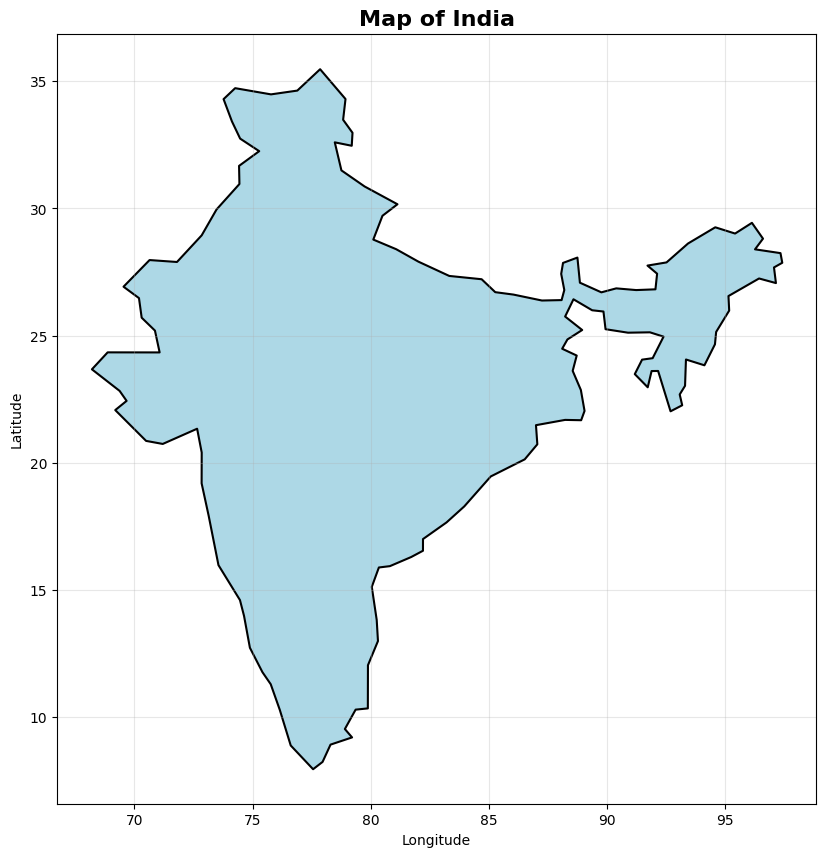

India bounds: [68.17664514  7.96553478 97.40256148 35.49400951]
India area: 277.92


/tmp/ipykernel_312767/1534387497.py:23: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  print(f"India area: {india.area.values[0]:.2f}")


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load world map (GeoPandas built-in datasets were removed in v1.0)
world_url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(world_url)

# Filter for India
name_col = "name" if "name" in world.columns else "ADMIN"
india = world[world[name_col] == "India"]

# Plot India
fig, ax = plt.subplots(figsize=(10, 10))
india.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=1.5)
ax.set_title("Map of India", fontsize=16, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)
plt.show()

# Print some info
print(f"India bounds: {india.bounds.values[0]}")
print(f"India area: {india.area.values[0]:.2f}")

Matrix shape: (200, 200)
Top-left 10x10 block:
 [[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


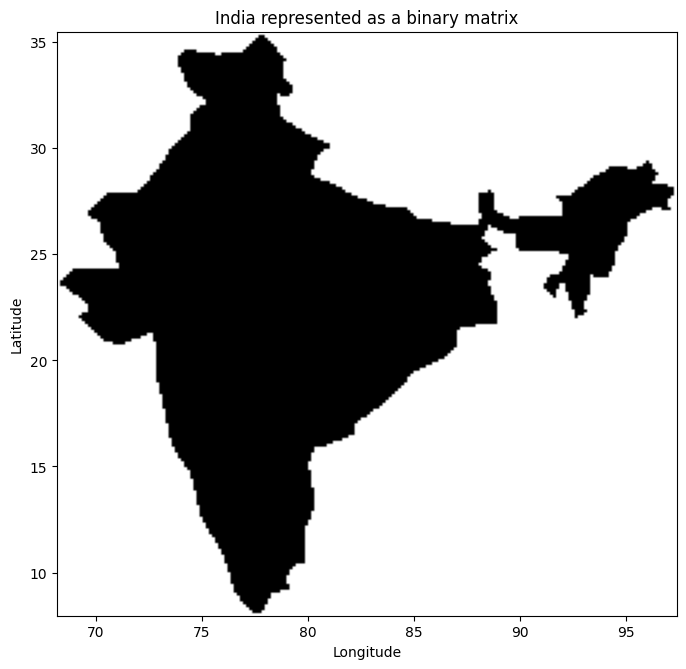

In [2]:
import numpy as np
from shapely import contains_xy

# Merge India geometry to a single shape
india_geom = india.geometry.union_all()

# Build a binary matrix over the bounding box
minx, miny, maxx, maxy = india_geom.bounds
n_rows, n_cols = 200, 200
xs = np.linspace(minx, maxx, n_cols)
ys = np.linspace(miny, maxy, n_rows)
X, Y = np.meshgrid(xs, ys)

india_matrix = contains_xy(india_geom, X, Y).astype(np.uint8)

print(f"Matrix shape: {india_matrix.shape}")
print("Top-left 10x10 block:\n", india_matrix[:10, :10])

plt.figure(figsize=(8, 8))
plt.imshow(
    india_matrix,
    origin="lower",
    cmap="gray_r",
    extent=[minx, maxx, miny, maxy],
    aspect="equal",
)
plt.title("India represented as a binary matrix")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Number of eigenvalues: 200
First 10 eigenvalues:
[ 71.83596755 +0.j          19.0723281 +12.80152339j
  19.0723281 -12.80152339j -10.52646814 +0.j
  -2.21814906 +8.20236374j  -2.21814906 -8.20236374j
  -5.12370754 +4.93138225j  -5.12370754 -4.93138225j
   5.37030554 +3.99150478j   5.37030554 -3.99150478j]


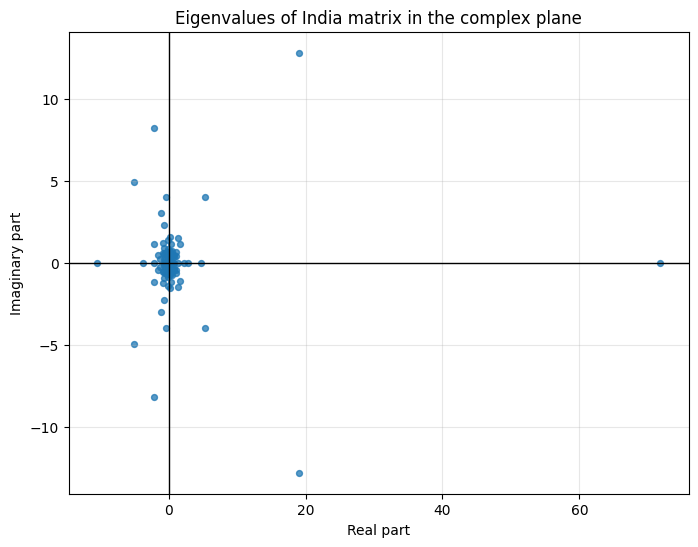

In [3]:
# Eigenvalues of the India binary matrix
A = india_matrix.astype(float)
eigs = np.linalg.eigvals(A)

print(f"Number of eigenvalues: {eigs.size}")
print("First 10 eigenvalues:")
print(eigs[:10])

plt.figure(figsize=(8, 6))
plt.scatter(eigs.real, eigs.imag, s=18, alpha=0.75, color="tab:blue")
plt.axhline(0, color="black", linewidth=1)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Real part")
plt.ylabel("Imaginary part")
plt.title("Eigenvalues of India matrix in the complex plane")
plt.grid(True, alpha=0.3)
plt.show()

Number of contour samples: 1024
DC term magnitude: 0.000000


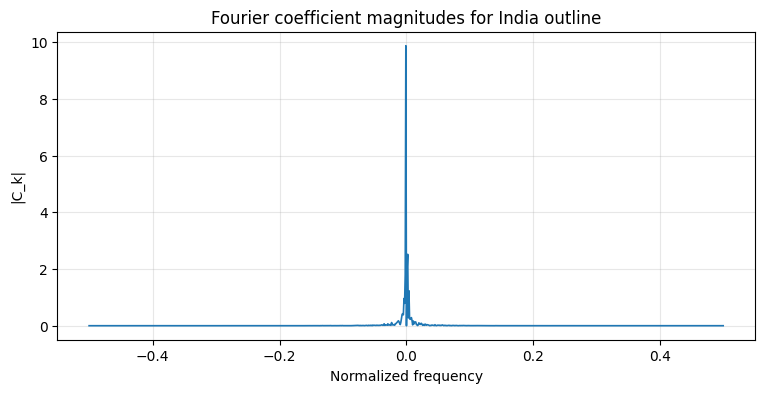

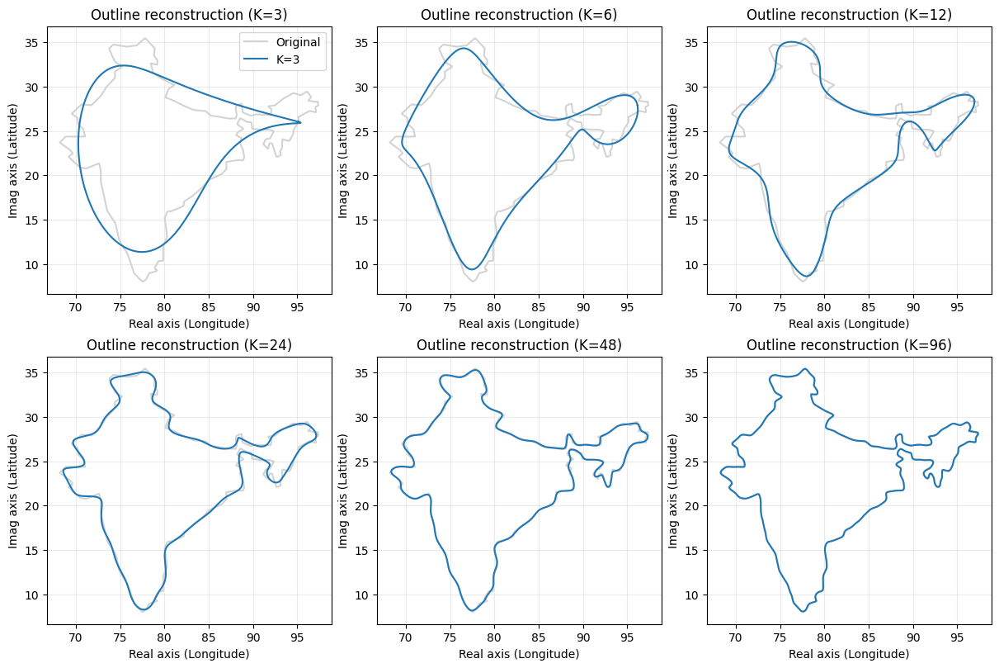

In [4]:
# Fourier decomposition of India's outline in the complex plane
geom = india.geometry.iloc[0]
if geom.geom_type == "MultiPolygon":
    poly = max(geom.geoms, key=lambda g: g.area)
else:
    poly = geom

coords = np.array(poly.exterior.coords)
z_raw = coords[:, 0] + 1j * coords[:, 1]

# Arc-length resampling for near-uniform spacing
segment_lengths = np.abs(np.diff(z_raw))
arc = np.concatenate(([0.0], np.cumsum(segment_lengths)))
N = 1024
target_arc = np.linspace(0.0, arc[-1], N, endpoint=False)
x_u = np.interp(target_arc, arc, coords[:, 0])
y_u = np.interp(target_arc, arc, coords[:, 1])
z = x_u + 1j * y_u

# Center and compute Fourier coefficients
z_center = z - z.mean()
C = np.fft.fft(z_center) / N
freq = np.fft.fftfreq(N)

print(f"Number of contour samples: {N}")
print(f"DC term magnitude: {np.abs(C[0]):.6f}")

# Show coefficient magnitudes in frequency domain
plt.figure(figsize=(9, 4))
plt.plot(np.fft.fftshift(freq), np.fft.fftshift(np.abs(C)), linewidth=1.2)
plt.title("Fourier coefficient magnitudes for India outline")
plt.xlabel("Normalized frequency")
plt.ylabel("|C_k|")
plt.grid(True, alpha=0.3)
plt.show()

# Reconstruct with increasing number of low-frequency pairs
k_values = [3, 6, 12, 24, 48, 96]
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)

for ax, K in zip(axes.ravel(), k_values):
    Ck = np.zeros_like(C)
    Ck[0] = C[0]
    Ck[1:K+1] = C[1:K+1]
    Ck[-K:] = C[-K:]

    zk = np.fft.ifft(Ck * N) + z.mean()

    ax.plot(z.real, z.imag, color="lightgray", linewidth=1.5, label="Original")
    ax.plot(zk.real, zk.imag, color="tab:blue", linewidth=1.5, label=f"K={K}")
    ax.set_title(f"Outline reconstruction (K={K})")
    ax.set_aspect("equal")
    ax.set_xlabel("Real axis (Longitude)")
    ax.set_ylabel("Imag axis (Latitude)")
    ax.grid(True, alpha=0.25)

axes[0, 0].legend(loc="best")
plt.show()

In [5]:
# Movie: Fourier outline reconstruction with increasing harmonics K
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# If this cell is run independently, rebuild Fourier coefficients from the India outline
if "C" not in globals() or "z" not in globals() or "N" not in globals():
    geom = india.geometry.iloc[0]
    if geom.geom_type == "MultiPolygon":
        poly = max(geom.geoms, key=lambda g: g.area)
    else:
        poly = geom

    coords = np.array(poly.exterior.coords)
    z_raw = coords[:, 0] + 1j * coords[:, 1]
    segment_lengths = np.abs(np.diff(z_raw))
    arc = np.concatenate(([0.0], np.cumsum(segment_lengths)))
    N = 1024
    target_arc = np.linspace(0.0, arc[-1], N, endpoint=False)
    x_u = np.interp(target_arc, arc, coords[:, 0])
    y_u = np.interp(target_arc, arc, coords[:, 1])
    z = x_u + 1j * y_u
    z_center = z - z.mean()
    C = np.fft.fft(z_center) / N

k_frames = np.unique(np.linspace(1, 128, 64, dtype=int))

fig, ax = plt.subplots(figsize=(7.5, 7.5))
base_line, = ax.plot(z.real, z.imag, color="lightgray", linewidth=1.2, label="Original")
recon_line, = ax.plot([], [], color="tab:blue", linewidth=2.0, label="Fourier reconstruction")
ax.set_aspect("equal")
ax.set_xlabel("Real axis (Longitude)")
ax.set_ylabel("Imag axis (Latitude)")
ax.grid(True, alpha=0.25)
ax.legend(loc="best")
title = ax.set_title("Fourier outline movie (K=1)")

pad_x = 0.8
pad_y = 0.8
ax.set_xlim(z.real.min() - pad_x, z.real.max() + pad_x)
ax.set_ylim(z.imag.min() - pad_y, z.imag.max() + pad_y)

def update(frame_idx):
    K = int(k_frames[frame_idx])
    Ck = np.zeros_like(C)
    Ck[0] = C[0]
    Ck[1:K+1] = C[1:K+1]
    Ck[-K:] = C[-K:]
    zk = np.fft.ifft(Ck * N) + z.mean()
    recon_line.set_data(zk.real, zk.imag)
    title.set_text(f"Fourier outline movie (K={K})")
    return recon_line, title

ani = FuncAnimation(fig, update, frames=len(k_frames), interval=120, blit=False, repeat=True)
plt.close(fig)

HTML(ani.to_jshtml())

In [6]:
# Trace the India map one point at a time from Fourier coefficients
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl

# Increase inline animation budget (MB) for larger JS animations
mpl.rcParams["animation.embed_limit"] = 80

# If this cell is run independently, rebuild Fourier coefficients from the India outline
if "C" not in globals() or "z" not in globals() or "N" not in globals():
    geom = india.geometry.iloc[0]
    if geom.geom_type == "MultiPolygon":
        poly = max(geom.geoms, key=lambda g: g.area)
    else:
        poly = geom

    coords = np.array(poly.exterior.coords)
    z_raw = coords[:, 0] + 1j * coords[:, 1]
    segment_lengths = np.abs(np.diff(z_raw))
    arc = np.concatenate(([0.0], np.cumsum(segment_lengths)))
    N = 1024
    target_arc = np.linspace(0.0, arc[-1], N, endpoint=False)
    x_u = np.interp(target_arc, arc, coords[:, 0])
    y_u = np.interp(target_arc, arc, coords[:, 1])
    z = x_u + 1j * y_u
    z_center = z - z.mean()
    C = np.fft.fft(z_center) / N

# Choose how many Fourier modes to keep
K = 160
Ck = np.zeros_like(C)
Ck[0] = C[0]
Ck[1:K+1] = C[1:K+1]
Ck[-K:] = C[-K:]

# Reconstructed closed curve from selected Fourier modes
z_rec = np.fft.ifft(Ck * N) + z.mean()

fig, ax = plt.subplots(figsize=(6, 6))
#ax.plot(z.real, z.imag, color="lightgray", linewidth=1.0, label="Original")
trace_line, = ax.plot([], [], color="tab:blue", linewidth=2.0, label=f"Trace (K={K})")
head_point, = ax.plot([], [], marker="o", markersize=5, color="tab:red")

ax.set_aspect("equal")
ax.set_xlabel("Real axis (Longitude)")
ax.set_ylabel("Imag axis (Latitude)")
ax.set_title("Fourier tracing: one point at a time")
ax.grid(True, alpha=0.25)
ax.legend(loc="best")

pad_x = 0.8
pad_y = 0.8
ax.set_xlim(z.real.min() - pad_x, z.real.max() + pad_x)
ax.set_ylim(z.imag.min() - pad_y, z.imag.max() + pad_y)

# Downsample frames to keep embedded animation size manageable
max_frames = 180
frame_indices = np.linspace(0, len(z_rec) - 1, max_frames, dtype=int)
frame_indices = np.unique(frame_indices)
n_frames = len(frame_indices)

def init():
    trace_line.set_data([], [])
    head_point.set_data([], [])
    return trace_line, head_point

def update(i):
    idx = int(frame_indices[i])
    x = z_rec.real[: idx + 1]
    y = z_rec.imag[: idx + 1]
    trace_line.set_data(x, y)
    head_point.set_data([z_rec.real[idx]], [z_rec.imag[idx]])
    return trace_line, head_point

ani_trace = FuncAnimation(
    fig,
    update,
    init_func=init,
    frames=n_frames,
    interval=40,
    blit=True,
    repeat=True,
)
plt.close(fig)

HTML(ani_trace.to_jshtml())

Let
$$
L=\frac{d^2}{dx^2}
$$
on the interval $[a,b]$, with inner product
$$
\langle u,v\rangle=\int_a^b u(x)\,\overline{v(x)}\,dx.
$$

First compute
$$
\langle Lu,v\rangle=\int_a^b u''\,\overline{v}\,dx
=\left[u'\overline{v}\right]_a^b-\int_a^b u'\,\overline{v'}\,dx.
$$

Next compute
$$
\langle u,Lv\rangle=\int_a^b u\,\overline{v''}\,dx
=\left[u\overline{v'}\right]_a^b-\int_a^b u'\,\overline{v'}\,dx.
$$

Subtracting gives
$$
\langle Lu,v\rangle-\langle u,Lv\rangle
=\left[u'\overline{v}-u\overline{v'}\right]_a^b.
$$

Therefore, for symmetry we require
$$
\left[u'\overline{v}-u\overline{v'}\right]_a^b=0
\quad\text{for all }u,v\text{ in the domain.}
$$

This boundary term is exactly where boundary conditions come from.
Typical choices are Dirichlet ($u(a)=u(b)=0$), Neumann ($u'(a)=u'(b)=0$), Robin, or periodic conditions.

For the operator
$$
L=\frac{d^2}{dx^2}
$$
on the interval
$$
[a,b],
$$
integration by parts gives the boundary term
$$
\left[u'\overline{v}-u\overline{v'}\right]_a^b
=
\left(u'(b)\overline{v(b)}-u(b)\overline{v'(b)}\right)
-
\left(u'(a)\overline{v(a)}-u(a)\overline{v'(a)}\right).
$$

With periodic boundary conditions
$$
u(a)=u(b),\quad u'(a)=u'(b),\quad
v(a)=v(b),\quad v'(a)=v'(b),
$$
we get
$$
u'(b)\overline{v(b)}-u(b)\overline{v'(b)}
=
u'(a)\overline{v(a)}-u(a)\overline{v'(a)}.
$$

Hence
$$
\left[u'\overline{v}-u\overline{v'}\right]_a^b=0.
$$
So the boundary contribution vanishes.

In [7]:
# Epicycle plot: India outline traced by rotating Fourier phasors
from matplotlib.patches import Circle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl
import numpy as np

mpl.rcParams["animation.embed_limit"] = 200

# Rebuild Fourier coefficients if needed
if "C" not in globals() or "z" not in globals() or "N" not in globals():
    geom = india.geometry.iloc[0]
    if geom.geom_type == "MultiPolygon":
        poly = max(geom.geoms, key=lambda g: g.area)
    else:
        poly = geom
    coords = np.array(poly.exterior.coords)
    z_raw = coords[:, 0] + 1j * coords[:, 1]
    segment_lengths = np.abs(np.diff(z_raw))
    arc = np.concatenate(([0.0], np.cumsum(segment_lengths)))
    N = 1024
    target_arc = np.linspace(0.0, arc[-1], N, endpoint=False)
    x_u = np.interp(target_arc, arc, coords[:, 0])
    y_u = np.interp(target_arc, arc, coords[:, 1])
    z = x_u + 1j * y_u
    z_center = z - z.mean()
    C = np.fft.fft(z_center) / N

# Number of epicycles (largest-amplitude modes first)
K_epi = 60

# Sort modes by amplitude descending
order = np.argsort(-np.abs(C))
selected = order[:K_epi]
selected_freqs = (np.fft.fftfreq(N) * N)[selected]   # integer frequencies
selected_C = C[selected]
radii = np.abs(selected_C)

# Precompute the phasor-chain positions for every frame
n_frames = 300
ts = np.linspace(0, N, n_frames, endpoint=False)
center_offset = z.mean()

# all_positions: (n_frames, K_epi+1) — chain of cumulative phasor tips
all_positions = np.empty((n_frames, K_epi + 1), dtype=complex)
for fi, t in enumerate(ts):
    pos = center_offset
    all_positions[fi, 0] = pos
    for i, (freq, coef) in enumerate(zip(selected_freqs, selected_C)):
        angle = np.angle(coef) + 2 * np.pi * freq * t / N
        pos = pos + np.abs(coef) * np.exp(1j * angle)
        all_positions[fi, i + 1] = pos

tips = all_positions[:, -1]   # final traced point per frame

# Build the figure
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_aspect("equal")
pad = 1.5
ax.set_xlim(z.real.min() - pad, z.real.max() + pad)
ax.set_ylim(z.imag.min() - pad, z.imag.max() + pad)
ax.set_title(f"India outline — Fourier epicycles (K={K_epi})")
ax.grid(True, alpha=0.2)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Create circle patches (one per epicycle)
circles = []
for r in radii:
    c = Circle((0, 0), r, fill=False, color="steelblue", linewidth=0.7, alpha=0.45)
    c.set_animated(True)
    ax.add_patch(c)
    circles.append(c)

# Arm lines connecting circle centres to their tips
arms = [ax.plot([], [], color="steelblue", linewidth=0.9, alpha=0.65)[0]
        for _ in range(K_epi)]

trace_line, = ax.plot([], [], color="tomato", linewidth=1.8, label=f"Trace (K={K_epi})")
head_dot,   = ax.plot([], [], "o", color="tomato", markersize=5)
ax.legend(loc="upper right")

def init():
    trace_line.set_data([], [])
    head_dot.set_data([], [])
    for arm in arms:
        arm.set_data([], [])
    return circles + arms + [trace_line, head_dot]

def update(frame):
    chain = all_positions[frame]
    for i in range(K_epi):
        circles[i].center = (chain[i].real, chain[i].imag)
        arms[i].set_data([chain[i].real, chain[i + 1].real],
                         [chain[i].imag, chain[i + 1].imag])
    trace_line.set_data(tips[: frame + 1].real, tips[: frame + 1].imag)
    head_dot.set_data([tips[frame].real], [tips[frame].imag])
    return circles + arms + [trace_line, head_dot]

ani_epi = FuncAnimation(
    fig, update, init_func=init,
    frames=n_frames, interval=40, blit=True, repeat=True,
)
plt.close(fig)
HTML(ani_epi.to_jshtml())